In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from tqdm import tqdm

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
X = df.drop("target",axis=1)
y = df["target"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [6]:
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,50]
min_leaf = [1,5,20,30,50]
scores = []
for d in depths:
    for s in min_split:
        for l in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26, max_depth=d, min_samples_split=s, min_samples_leaf=l)
            pipe = Pipeline([("TREE",dtc)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d,s,l,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","L","Scores"])
df_scores.sort_values("Scores",ascending=False)

,D,S,L,Scores
86,5.0,5,5,0.813187
91,5.0,10,5,0.813187
81,5.0,2,5,0.813187
111,6.0,10,5,0.802198
131,7.0,10,5,0.802198
...,...,...,...,...
67,4.0,5,20,0.670330
47,3.0,5,20,0.670330
122,7.0,2,20,0.670330
102,6.0,2,20,0.670330


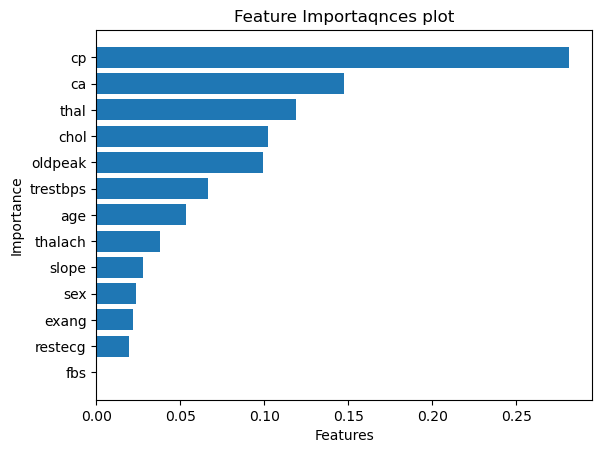

In [7]:
best_tree = DecisionTreeClassifier(random_state=26,max_depth=7,
                                  min_samples_split=5,min_samples_leaf=1)
best_tree.fit(X,y)
df_imp = pd.DataFrame({"features":list(X.columns),
                       "importance": best_tree.feature_importances_})
# plt.figure(figsize=(16,10))
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp["features"],df_imp["importance"])
plt.title("Feature Importaqnces plot")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

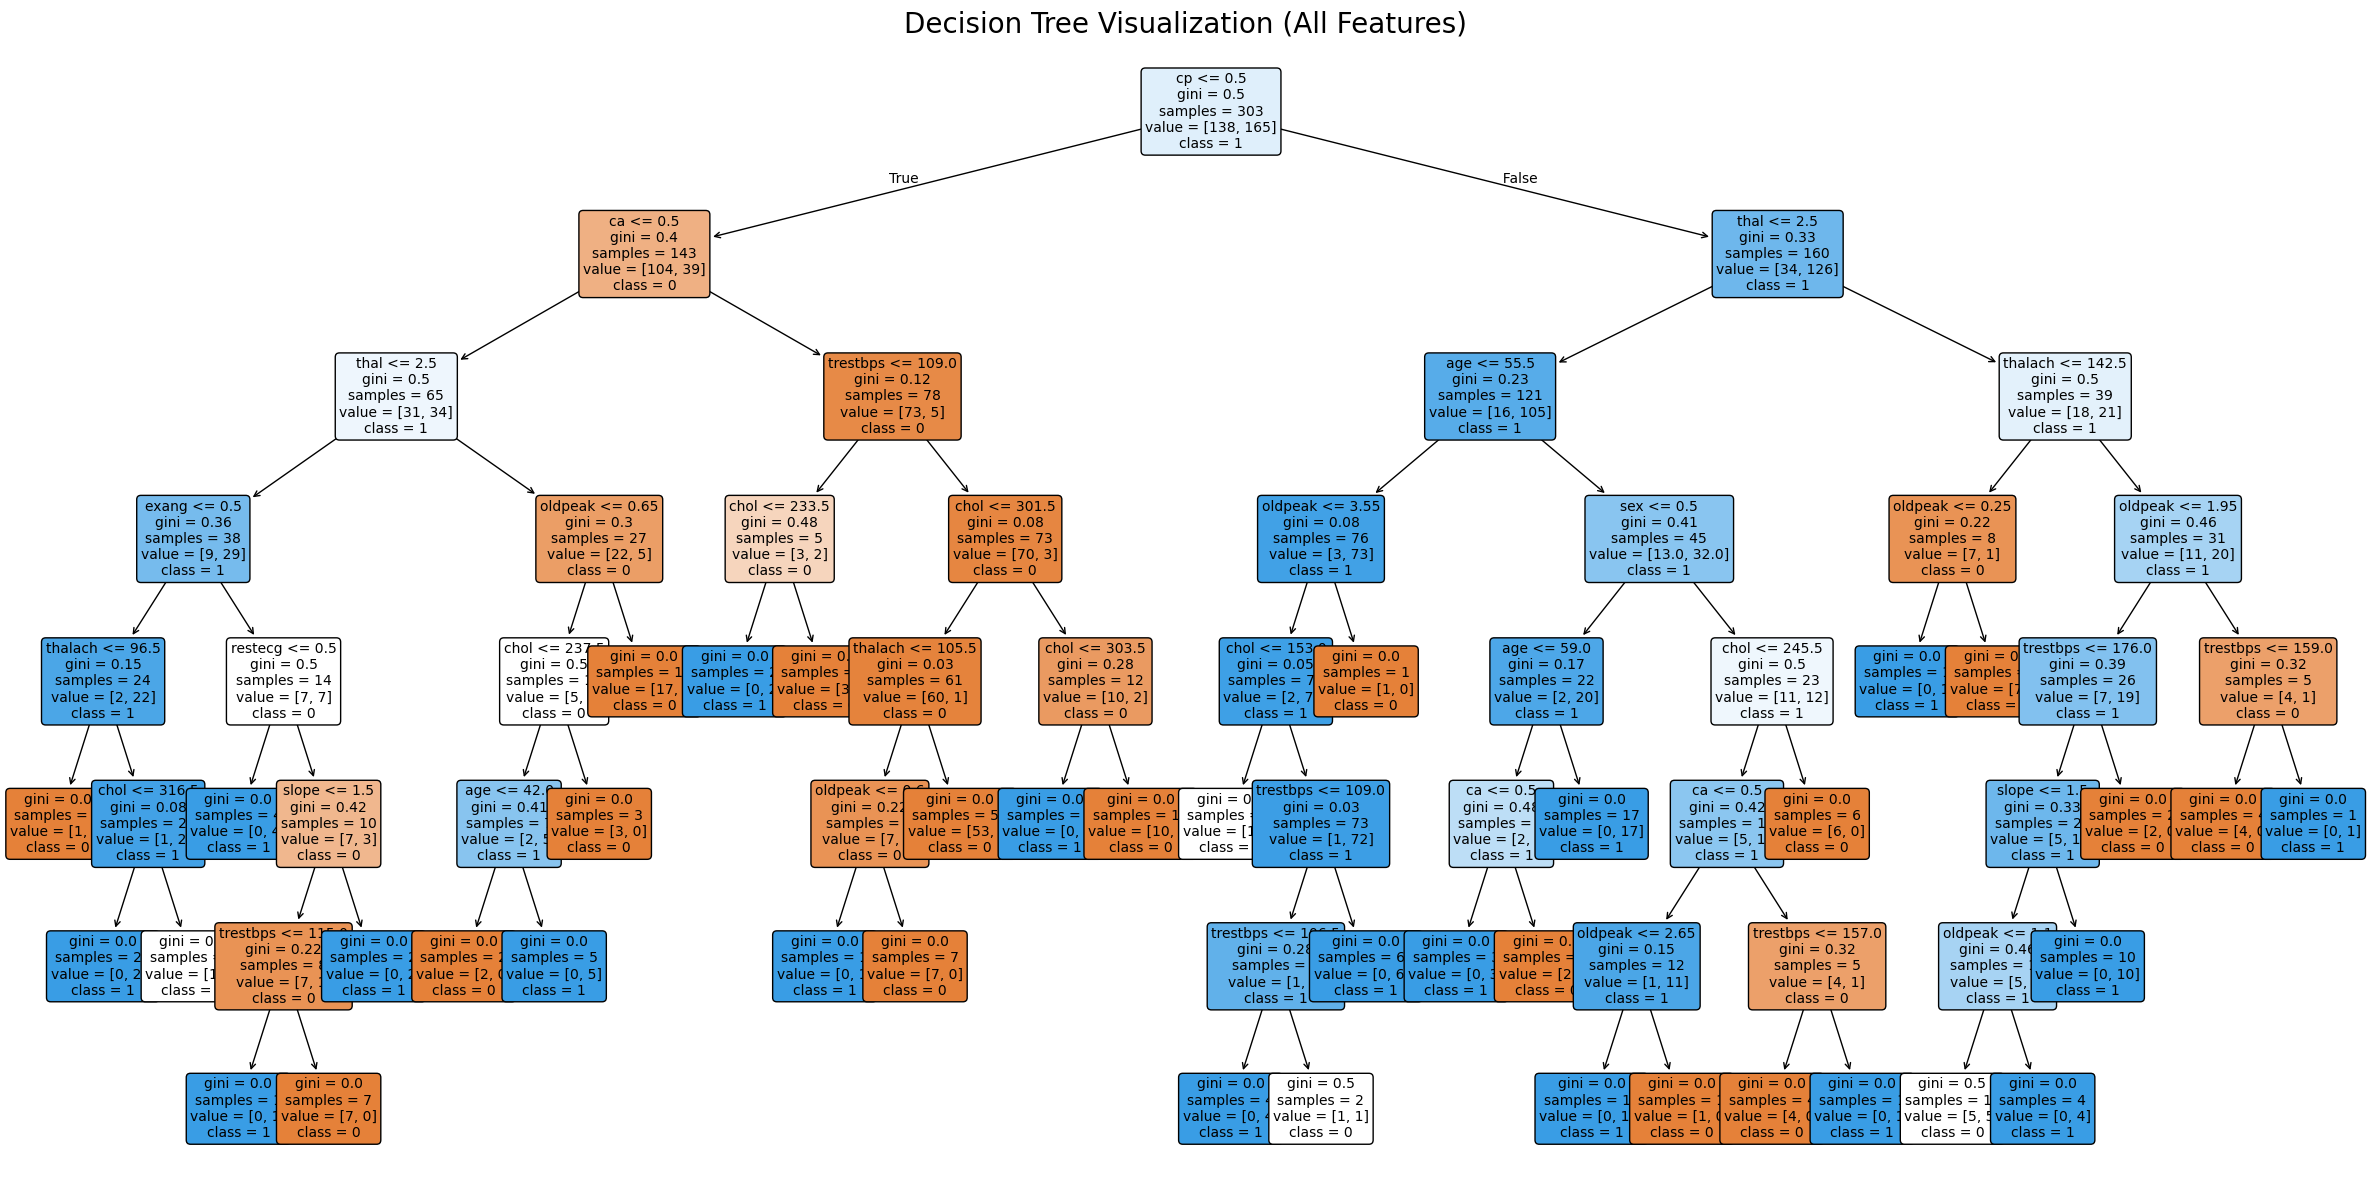

In [8]:
from sklearn.tree import plot_tree
plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,  # The model you already trained
    feature_names=list(X.columns),  # Use the transformed column names
    class_names=best_tree.classes_.astype(str),  # Map numeric to class names
    filled=True,  # Color nodes by dominant class
    rounded=True,  # Beautify nodes
    fontsize=10,  # Adjust size of text inside nodes
    precision=2  # Number of decimal places for split values
)

plt.title("Decision Tree Visualization (All Features)", fontsize=20)
plt.tight_layout()
plt.show()